In [1]:
# Imported libraries for data cleaning

from sklearn.impute import SimpleImputer
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

In [2]:
# Loaded the used car dataset
gs=pd.read_csv("/content/Global Superstore Dataset.csv")
gs

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,CA-2017-152156,08-11-2017,11-11-2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,CA-2017-152156,08-11-2017,11-11-2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,CA-2017-138688,12-06-2017,16-06-2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,US-2016-108966,11-10-2016,18-10-2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,US-2016-108966,11-10-2016,18-10-2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9795,CA-2017-125920,21-05-2017,28-05-2017,Standard Class,SH-19975,Sally Hughsby,Corporate,United States,Chicago,Illinois,60610.0,Central,OFF-BI-10003429,Office Supplies,Binders,"Cardinal HOLDit! Binder Insert Strips,Extra St...",3.7980
9796,CA-2016-128608,12-01-2016,17-01-2016,Standard Class,CS-12490,Cindy Schnelling,Corporate,United States,Toledo,Ohio,43615.0,East,OFF-AR-10001374,Office Supplies,Art,"BIC Brite Liner Highlighters, Chisel Tip",10.3680
9797,CA-2016-128608,12-01-2016,17-01-2016,Standard Class,CS-12490,Cindy Schnelling,Corporate,United States,Toledo,Ohio,43615.0,East,TEC-PH-10004977,Technology,Phones,GE 30524EE4,235.1880
9798,CA-2016-128608,12-01-2016,17-01-2016,Standard Class,CS-12490,Cindy Schnelling,Corporate,United States,Toledo,Ohio,43615.0,East,TEC-PH-10000912,Technology,Phones,Anker 24W Portable Micro USB Car Charger,26.3760


In [3]:
# Remark: Display the first 5 rows
gs.head()


,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,CA-2017-152156,08-11-2017,11-11-2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,CA-2017-152156,08-11-2017,11-11-2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,CA-2017-138688,12-06-2017,16-06-2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,US-2016-108966,11-10-2016,18-10-2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,US-2016-108966,11-10-2016,18-10-2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [4]:

# Remark: Check the total number of rows and columns

gs.shape


(9800, 17)

In [5]:

# Remark: Display all column names

gs.columns.tolist()


['Order ID',
 'Order Date',
 'Ship Date',
 'Ship Mode',
 'Customer ID',
 'Customer Name',
 'Segment',
 'Country',
 'City',
 'State',
 'Postal Code',
 'Region',
 'Product ID',
 'Category',
 'Sub-Category',
 'Product Name',
 'Sales']

In [6]:

# Remark: Check column data types and non-null values

gs.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order ID       9800 non-null   object 
 1   Order Date     9800 non-null   object 
 2   Ship Date      9800 non-null   object 
 3   Ship Mode      9800 non-null   object 
 4   Customer ID    9800 non-null   object 
 5   Customer Name  9800 non-null   object 
 6   Segment        9800 non-null   object 
 7   Country        9800 non-null   object 
 8   City           9800 non-null   object 
 9   State          9800 non-null   object 
 10  Postal Code    9789 non-null   float64
 11  Region         9800 non-null   object 
 12  Product ID     9800 non-null   object 
 13  Category       9800 non-null   object 
 14  Sub-Category   9800 non-null   object 
 15  Product Name   9800 non-null   object 
 16  Sales          9800 non-null   float64
dtypes: float64(2), object(15)
memory usage: 1.3+ MB


In [7]:
# Remark: Generate descriptive statistics for numerical columns

gs.describe()


,Postal Code,Sales
count,9789.000000,9800.000000
mean,55273.322403,230.769059
std,32041.223413,626.651875
min,1040.000000,0.444000
25%,23223.000000,17.248000
50%,58103.000000,54.490000
75%,90008.000000,210.605000
max,99301.000000,22638.480000


In [8]:

# Remark: Count missing values in each column

gs.isnull().sum()


,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0
State,0


In [9]:

# Remark: Count duplicate records

gs.duplicated().sum()


np.int64(1)

In [10]:

# Remark: Count unique values in each column

gs.nunique()


,0
Order ID,4922
Order Date,1230
Ship Date,1326
Ship Mode,4
Customer ID,793
Customer Name,793
Segment,3
Country,1
City,529
State,49


In [11]:

# Remark: Preserve the original dataset before cleaning

gs_clean = gs.copy()


In [12]:

# Remark: Remove duplicate records from the working dataset

gs_clean = gs_clean.drop_duplicates()

print("Original shape:", gs.shape)
print("Cleaned shape:", gs_clean.shape)


Original shape: (9800, 17)
Cleaned shape: (9799, 17)


In [13]:

# Remark: Identify columns containing missing values

gs_clean.isnull().sum()[gs_clean.isnull().sum() > 0]


,0
Postal Code,11


In [14]:

# Remark: Review data types before converting columns

gs_clean.dtypes


,0
Order ID,object
Order Date,object
Ship Date,object
Ship Mode,object
Customer ID,object
Customer Name,object
Segment,object
Country,object
City,object
State,object


In [15]:

# Remark: Convert order and shipping dates into datetime format

for col in ["Order Date", "Ship Date"]:
    if col in gs_clean.columns:
        gs_clean[col] = pd.to_datetime(
            gs_clean[col], errors="coerce"
        )

gs_clean.dtypes


,0
Order ID,object
Order Date,datetime64[ns]
Ship Date,datetime64[ns]
Ship Mode,object
Customer ID,object
Customer Name,object
Segment,object
Country,object
City,object
State,object


In [16]:

# Remark: Standardize column names for easier coding

gs_clean.columns = (
    gs_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

gs_clean.columns.tolist()


['order_id',
 'order_date',
 'ship_date',
 'ship_mode',
 'customer_id',
 'customer_name',
 'segment',
 'country',
 'city',
 'state',
 'postal_code',
 'region',
 'product_id',
 'category',
 'sub_category',
 'product_name',
 'sales']

In [17]:

# Remark: Examine relationships between numerical variables

numeric_data = gs_clean.select_dtypes(include="number")

numeric_data.corr()


,postal_code,sales
postal_code,1.000000,-0.024064
sales,-0.024064,1.000000


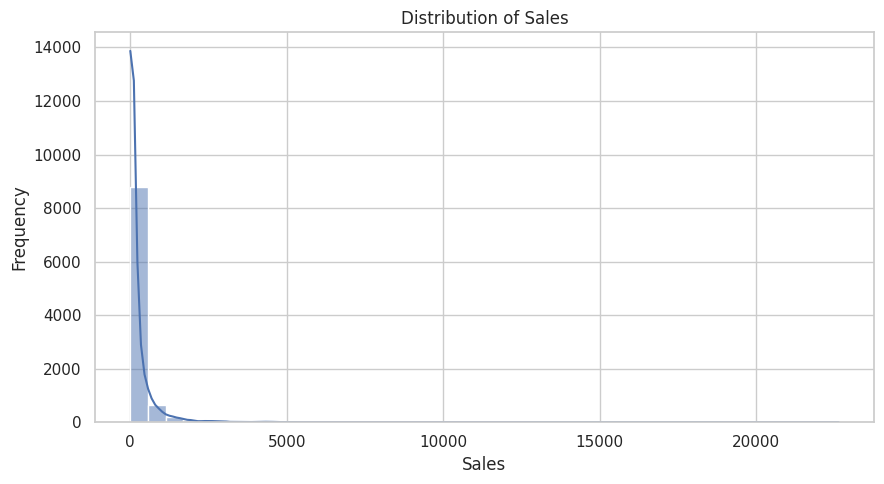

In [18]:

# Remark: Visualize the distribution of sales

sns.set_theme(style="whitegrid")

if "sales" in gs_clean.columns:
    plt.figure(figsize=(9, 5))
    sns.histplot(gs_clean["sales"].dropna(), bins=40, kde=True)
    plt.title("Distribution of Sales")
    plt.xlabel("Sales")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()
else:
    print("Sales column not found.")


In [19]:

# Remark: Visualize the distribution of profit

if "profit" in gs_clean.columns:
    plt.figure(figsize=(9, 5))
    sns.histplot(gs_clean["profit"].dropna(), bins=40, kde=True)
    plt.title("Distribution of Profit")
    plt.xlabel("Profit")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()
else:
    print("Profit column not found.")


Profit column not found.


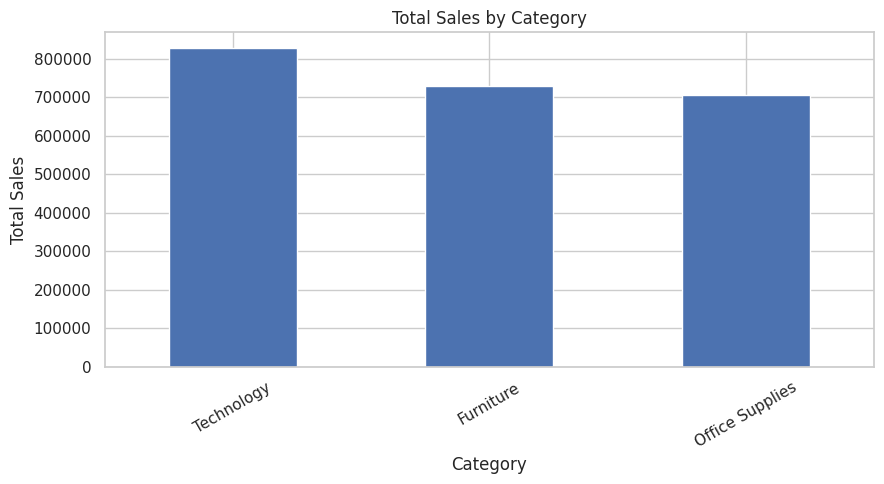

In [20]:

# Remark: Compare total sales across product categories

if {"category", "sales"}.issubset(gs_clean.columns):
    category_sales = (
        gs_clean.groupby("category")["sales"]
        .sum()
        .sort_values(ascending=False)
    )

    category_sales.plot(kind="bar", figsize=(9, 5))
    plt.title("Total Sales by Category")
    plt.xlabel("Category")
    plt.ylabel("Total Sales")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()
else:
    print("Required columns not found.")


In [21]:

# Remark: Compare total profit across product categories

if {"category", "profit"}.issubset(gs_clean.columns):
    category_profit = (
        gs_clean.groupby("category")["profit"]
        .sum()
        .sort_values(ascending=False)
    )

    category_profit.plot(kind="bar", figsize=(9, 5))
    plt.title("Total Profit by Category")
    plt.xlabel("Category")
    plt.ylabel("Total Profit")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()
else:
    print("Required columns not found.")


Required columns not found.


region
West       710219.6845
East       669237.3540
Central    492646.9132
South      389151.4590
Name: sales, dtype: float64


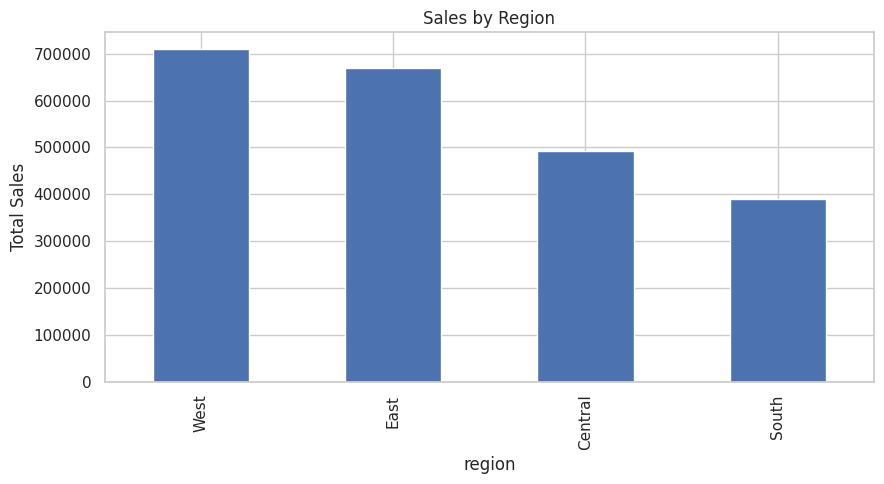

In [22]:

# Remark: Identify regions contributing the highest sales

if {"region", "sales"}.issubset(gs_clean.columns):
    region_sales = (
        gs_clean.groupby("region")["sales"]
        .sum()
        .sort_values(ascending=False)
    )

    print(region_sales)

    region_sales.plot(kind="bar", figsize=(9, 5))
    plt.title("Sales by Region")
    plt.ylabel("Total Sales")
    plt.tight_layout()
    plt.show()
else:
    print("Required columns not found.")


product_name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: sales, dtype: float64


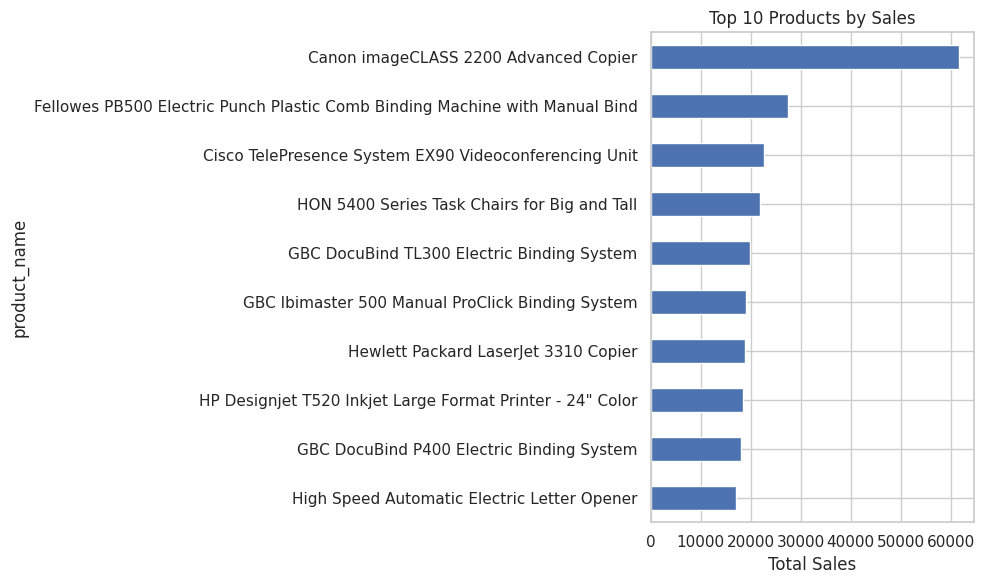

In [23]:

# Remark: Find the top 10 products by total sales

product_col = next(
    (c for c in ["product_name", "product"] if c in gs_clean.columns),
    None
)

if product_col and "sales" in gs_clean.columns:
    top_products = (
        gs_clean.groupby(product_col)["sales"]
        .sum()
        .sort_values(ascending=False)
        .head(10)
    )

    print(top_products)

    top_products.sort_values().plot(kind="barh", figsize=(10, 6))
    plt.title("Top 10 Products by Sales")
    plt.xlabel("Total Sales")
    plt.tight_layout()
    plt.show()
else:
    print("Product name or sales column not found.")


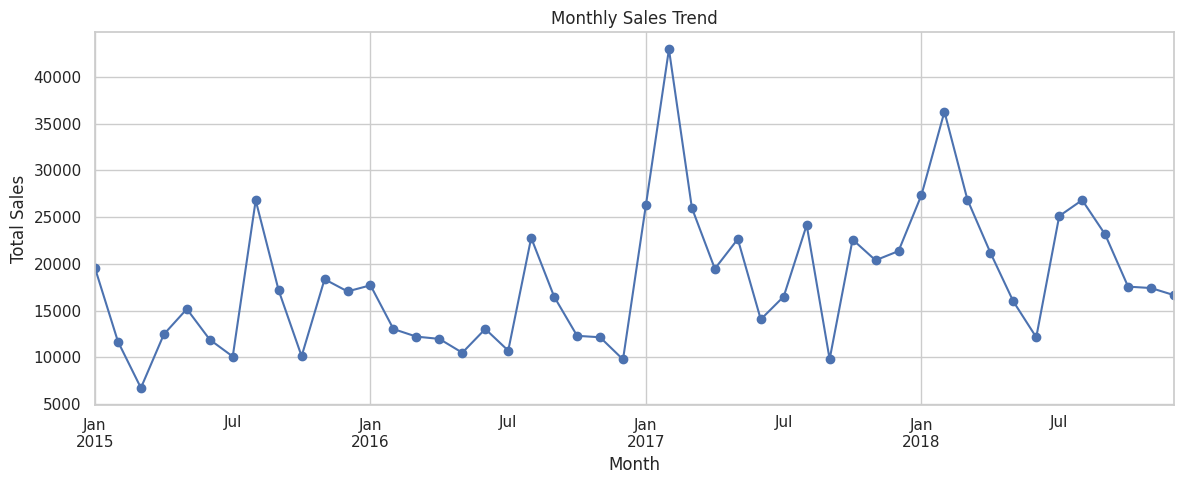

In [24]:

# Remark: Analyze monthly sales trends over time

if {"order_date", "sales"}.issubset(gs_clean.columns):
    monthly_sales = (
        gs_clean.dropna(subset=["order_date"])
        .set_index("order_date")["sales"]
        .resample("MS")
        .sum()
    )

    monthly_sales.plot(figsize=(12, 5), marker="o")
    plt.title("Monthly Sales Trend")
    plt.xlabel("Month")
    plt.ylabel("Total Sales")
    plt.tight_layout()
    plt.show()
else:
    print("Order date or sales column not found.")


In [25]:

# Remark: Calculate key business performance indicators

if "sales" in gs_clean.columns:
    print("Total Sales:", round(gs_clean["sales"].sum(), 2))
    print("Average Sales per Row:", round(gs_clean["sales"].mean(), 2))

if "profit" in gs_clean.columns:
    print("Total Profit:", round(gs_clean["profit"].sum(), 2))
    print("Average Profit per Row:", round(gs_clean["profit"].mean(), 2))

print("Total Records:", len(gs_clean))


Total Sales: 2261255.41
Average Sales per Row: 230.76
Total Records: 9799


In [26]:

# Remark: Save the cleaned dataset as a CSV file

gs_clean.to_csv("retail_sales_cleaned.csv", index=False)

print("Cleaned dataset exported successfully.")


Cleaned dataset exported successfully.


In [27]:

# Remark: Download the cleaned dataset to your computer

from google.colab import files

files.download("retail_sales_cleaned.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>